# Knob table: does any knob make Qwen3-8B write a different algorithm?

**Artifact `art_3tH2xtoZ7Gj2`: record repair and novelty audit of algorithm bans (iteration 3, Step 0, CPU only).**

The study behind this artifact asks how prompt-level **algorithm bans** move a code model's choice of algorithm. It
uses Qwen3-8B, with Llama-3.1-8B-Instruct as a second model family, and two path-search tasks throughout:

* **T1**, an unweighted grid shortest path, where the model's default ("modal") answer is **BFS**;
* **T2**, a weighted shortest path, where the default is **Dijkstra**.

`eval.py` generates nothing. It repairs the iteration-2 record from data already on disk and answers the novelty
question. It dispatches ten sections:

| `--section` | step | what it computes | in this demo |
|---|---|---|---|
| `inventory` | S0 | input inventory, label map | – |
| `c1` | 0a | C1 likelihood diagnostics (argmax vs landing, implied mass, bootstrap vs replicate noise, AIM null) | – |
| `manifold` | 0b | exp9 activation geometry at g16 with nulls and planted-loop power | – |
| `judges` | 0c | blind LLM judges for the novelty audit (paid; responses cached) | – |
| `novelty` | 0c | final classes, kappa, controls: **0 of 78 correct out-of-catalogue programs is a novel algorithm** | – |
| `llama` | 0d | Llama correct-only compositions and Hill numbers | – |
| **`knob`** | **0e** | **knob table: algorithm diversity against pass-rate cost for every experimental knob** | **runs here** |
| `positioning` | 0f | dated positioning quotes | – |
| `corrections` | 0h | 12 record corrections | – |
| `assemble` | – | `full/mini/preview_eval_out.json` | – |

Most sections read about 1 GB of dependency files: activation states, likelihood cells and cached judge responses.
Those cannot ship to Colab. This notebook therefore runs **section (0e), the knob table**, end to end. It uses the
original code of `eval.py`, `common/stats.py` and `sections/s0e_knob.py`, fed with real per-program records: **87 of
the 306 knob-table units, 8,470 generated programs**. They come from `mini_demo_data.json`, a curated subset of the
evaluation's `knob_table` dataset.

**The question.** Is temperature the "creativity knob"? What about a random seed string in the prompt, a "make a fully
novel algorithm" instruction, banning the usual algorithm, or steering the activations?

* **Diversity is measured by rarefied Hill-1 at depth 25.** This is the effective number of distinct algorithms among
  25 correct programs that also respect the ban, averaged over subsamples. A value of 1 means the same algorithm every
  time; 2 means two equally common algorithms.
* **Cost is measured in pass points.** These are the percentage points of pass rate that a knob loses against its
  reference row, which is the experiment's own baseline.

**Published verdict on the full table:** among 108 rankable knob rows costing fewer than 20 pass points, none reaches
Hill-1 of 2. The best is a *semantic seed* on T2, at 1.940 (90% interval 1.770 to 2.094) for 7 pass points.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (eval.py logs through it)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- eval.py ---
import argparse
import json
import resource
import sys
import time
from pathlib import Path

from loguru import logger

# --- sections/s0e_knob.py, common/stats.py, common/paths.py ---
import math
import re
from collections import Counter, defaultdict
from typing import Any, Iterable, Sequence

import numpy as np
import pandas as pd
from scipy.stats import norm

# --- notebook addition: plotting ---
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-3/evaluation-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(f"dataset {data['dataset']!r}: {data['n_units']} units, {data['n_programs']} programs")
print("selection:", data["selection"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'knob_table': 87 units, 8470 programs
selection: every exp6 unit (temperature x top-k/top-p x thinking grid, context seeds, prompt instructions, forced controls, generate-then-select), the exp1 and exp9 prompt bans (single, TOP, TOP5, ARC, SCATTER) and the exp4 activation-steering rows, each with its reference row


## Configuration

All tunable parameters are defined here.

* **`eval.py` command line.** The first group mirrors its options. Only `SECTION = "knob"` can run in this demo,
  because the other sections need dependency files that are not shipped.
* **Knob-section settings.** The second group holds the Monte-Carlo sizes and the ranking threshold that
  `sections/s0e_knob.py` hard-codes. They are set to the **original values**, because the whole section runs in a few
  seconds on the 87 demo units.
* **Quick smoke test.** Use `N_UNITS = 10`, `KNOB_N_SUB = 2`, `KNOB_N_BOOT = 2` and `KNOB_N_SUB_BOOT = 2`.
* **Keep `DEPTH` at 25.** It is part of how the statistic is defined, not a compute budget.

In [5]:
# --- eval.py command line (defaults of its argparse) ---
SECTION = "knob"        # the only section whose inputs ship with this demo (eval.py default: "all")
N_BOOT = 2000           # --n-boot  (c1 section)
N_SIM = 10000           # --n-sim   (c1 section)
N_PERM = 500            # --n-perm  (manifold section)
N_NULL = 200            # --n-null  (manifold section)
N_POWER = 200           # --n-power (manifold section)
WORKERS = 6             # --workers (manifold section)

# --- sections/s0e_knob.py (literals in the original, exposed here) ---
DEPTH = 25              # rarefaction depth: correct compliant programs per subsample (original 25)
KNOB_N_SUB = 1000       # subsamples per rarefied Hill-1 estimate (original 1000)
KNOB_N_BOOT = 2000      # bootstrap resamples for the 90% interval (original 2000)
KNOB_N_SUB_BOOT = 200   # subsamples inside each bootstrap resample (original 200)
MAX_POINTS = 20.0       # ranking keeps KNOB rows costing < this many pass points (original 20)

# --- demo data size ---
N_UNITS = None          # first N units of mini_demo_data.json (None = all 87; the full table has 306)

## Output folders, seed and JSON writer (from `common/paths.py`)

In the repository, `common/paths.py` maps each of the 11 dependency artifacts (exp1 to exp12) to a folder, and every
number is cited as `<artifact_id>:<relative path>`. Here the per-program records come from `mini_demo_data.json`, so
only what the knob section uses is kept:

* the output folders;
* the global seed;
* `write_json`, which turns NaN into `null` so the JSON stays standard.

The repository root becomes the notebook's working directory.

In [6]:
WS = Path.cwd()   # (demo) the original is Path(__file__).resolve().parent.parent, the repository root

RESULTS = WS / "results"
TABLES = WS / "tables"
LOGS = WS / "logs"
SEED = 20261020
TABLES.mkdir(parents=True, exist_ok=True)   # (demo) in the repository, earlier sections create tables/


def _default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        v = float(o)
        return None if not math.isfinite(v) else v
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (set, tuple)):
        return list(o)
    if isinstance(o, Path):
        return str(o)
    return str(o)


def clean(o: Any) -> Any:
    """Recursively replace non-finite floats by None so the JSON is standard."""
    import numpy as np

    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (float, np.floating)):
        v = float(o)
        return v if math.isfinite(v) else None
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.ndarray):
        return clean(o.tolist())
    if isinstance(o, np.bool_):
        return bool(o)
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(clean(obj), indent=indent, default=_default))
    tmp.replace(p)

## Logging and the list of sections (from `eval.py`)

`eval.py` logs every step to the screen and to `logs/run.log`, and declares its ten sections in run order.

In [7]:
LOGS.mkdir(parents=True, exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(LOGS / "run.log"), rotation="30 MB", level="DEBUG")

SECTIONS = ["inventory", "c1", "manifold", "judges", "novelty", "llama", "knob", "positioning", "corrections",
            "assemble"]

## Statistics toolkit (from `common/stats.py`)

These are the functions the knob section calls, copied unchanged:

* **`wilson(k, n)`** gives the Wilson score interval of a proportion. It is used for the share of the second most
  common algorithm.
* **`newcombe_diff(k1, n1, k2, n2)`** gives the Newcombe hybrid-score interval of a difference of two proportions. It
  is used for the pass points: the reference pass rate minus the unit's pass rate, in percentage points.
* **`hill1(counts)`** is the Hill number of order 1, $\exp(H)$ with $H = -\sum_i p_i \ln p_i$. It is the effective
  number of equally common algorithms.
* **`rarefied_hill1(counts, depth, n_sub)`** is the mean of $\exp(H)$ over `n_sub` subsamples of `depth` programs
  drawn without replacement (multivariate hypergeometric). Rarefying makes rows with different numbers of correct
  programs comparable.
* **`boot_rarefied_hill1(...)`** gives a percentile interval of the rarefied Hill-1. Each bootstrap draw resamples
  the row's programs (multinomial) and then rarefies the resample.

The repository's `common/stats.py` also contains Cohen's kappa, Kish ESS and the PSIS $\hat k$. The c1 and novelty
sections use them, so they are not repeated here.

In [8]:
# common/stats.py: Wilson / Newcombe intervals and Hill numbers (plug-in, rarefied) -- the functions section 0e uses


def wilson(k: int, n: int, conf: float = 0.95) -> tuple[float, float]:
    if n <= 0:
        return (math.nan, math.nan)
    z = norm.ppf(1 - (1 - conf) / 2)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe_diff(k1: int, n1: int, k2: int, n2: int, conf: float = 0.95) -> tuple[float, float, float]:
    """Newcombe hybrid-score interval (method 10) for p1 - p2 of independent proportions. Returns (d, lo, hi)."""
    if n1 <= 0 or n2 <= 0:
        return (math.nan, math.nan, math.nan)
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1, conf)
    l2, u2 = wilson(k2, n2, conf)
    d = p1 - p2
    lo = d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return (d, lo, hi)


def hill1(counts: Sequence[float]) -> float:
    c = np.asarray(counts, dtype=float)
    c = c[c > 0]
    n = c.sum()
    if n <= 0:
        return math.nan
    p = c / n
    return float(math.exp(-(p * np.log(p)).sum()))


def _hill_rows(M: np.ndarray) -> np.ndarray:
    n = M.sum(axis=1, keepdims=True)
    p = np.where(M > 0, M / np.maximum(n, 1), 1.0)
    return np.exp(-(np.where(M > 0, (M / np.maximum(n, 1)) * np.log(p), 0.0)).sum(axis=1))


def rarefied_hill1(counts: Sequence[float], depth: int, n_sub: int = 1000,
                   rng: np.random.Generator | None = None) -> float:
    """Mean over n_sub subsamples of size `depth` drawn WITHOUT replacement of exp(Shannon) of the subsample."""
    c = np.asarray(counts, dtype=np.int64)
    c = c[c > 0]
    if c.sum() < depth or depth <= 0:
        return math.nan
    if len(c) == 1:
        return 1.0
    rng = rng or np.random.default_rng(0)
    M = rng.multivariate_hypergeometric(c, depth, size=n_sub)
    return float(_hill_rows(M.astype(float)).mean())


def boot_rarefied_hill1(counts: Sequence[float], depth: int, n_boot: int = 2000, n_sub: int = 200,
                        rng: np.random.Generator | None = None, conf: float = 0.90) -> tuple[float, float]:
    """Percentile interval of rarefied Hill-1 over multinomial resamples of the row (programs resampled)."""
    c = np.asarray(counts, dtype=np.int64)
    c = c[c > 0]
    n = int(c.sum())
    if n < depth:
        return (math.nan, math.nan)
    rng = rng or np.random.default_rng(1)
    p = c / n
    vals = np.empty(n_boot)
    for b in range(n_boot):
        cb = rng.multinomial(n, p)
        cb = cb[cb > 0]
        if len(cb) == 1:
            vals[b] = 1.0
            continue
        M = rng.multivariate_hypergeometric(cb, depth, size=n_sub)
        vals[b] = _hill_rows(M.astype(float)).mean()
    a = (1 - conf) / 2
    return (float(np.quantile(vals, a)), float(np.quantile(vals, 1 - a)))

## Per-program rows (replaces `common/rows.py: iter_rows()`)

In the repository, `iter_rows()` reads every origin file of the dependency artifacts. It normalises each generated
program to one row: experiment, task, model, condition, banned set, decoding key, the algorithm it was labelled as,
and whether it passed the hidden tests. Labels use the two analysis catalogues; anything else is `other` or
`unparseable`.

* **T1, 6 labels:** `bfs`, `dfs`, `bibfs` (bidirectional BFS), `iddfs`, `astar_gbfs` (A* or greedy best-first),
  `dijkstra`.
* **T2, 5 labels:** `dijkstra`, `bf_spfa` (Bellman-Ford or SPFA), `bidijkstra`, `floyd`, `dial`.

For each unit, `mini_demo_data.json` stores those rows compactly as `[label, label_fine, passed]` in source-file order,
plus the unit fields that all its rows share. The cell below expands them back into rows of the same schema, keeping
only the fields the knob section reads. `_rows()` is the unchanged `eval.py` helper.

In [9]:
# common/rows.py (excerpt): the modal (default) algorithm of each task and the analysis catalogues
MODAL = {"t1": "bfs", "t2": "dijkstra"}
T1_K6 = ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"]          # exp7 analysis catalogue (T1)
T2_K5 = ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]               # exp7 analysis catalogue (T2)


def iter_rows(include_exp12_extra: bool = False):
    """(demo) Per-program rows of the demo units in the row schema of common/rows.py (only the fields the knob section
    reads). The original reads and normalises every origin file of the 11 dependency artifacts."""
    for ex in data["examples"][:N_UNITS]:
        u = ex["unit"]
        for label, label_fine, passed in ex["programs"]:
            yield {"exp": u["exp"], "task": u["task"], "model": u["model"], "condition": u["condition"],
                   "banned_set": u["banned_set"], "decoding_key": u["decoding_key"], "label": label,
                   "label_fine": label_fine, "passed": passed, "source": u["source"], "arm": u["arm"]}


# eval.py
def _rows(include_extra: bool = False):
    return list(iter_rows(include_exp12_extra=include_extra))


_demo_rows = _rows()
print(f"{len(_demo_rows)} programs in {len(data['examples'][:N_UNITS])} units\n")
print(pd.DataFrame(_demo_rows).groupby(["exp", "task"]).agg(
    programs=("label", "size"), passed=("passed", lambda s: int(sum(v is True for v in s))),
    conditions=("condition", "nunique"), decodings=("decoding_key", "nunique")).to_string())
print("\nfirst row:", _demo_rows[0])

8470 programs in 87 units

           programs  passed  conditions  decodings
exp  task                                         
exp1 t1         750     638           5          2
     t2         600     595           3          2
exp4 t2        1100     828          10          1
exp6 t1        2620    2481          15         17
     t2        2600    2491          14         17
exp9 t1         600     373           6          1
     t2         200     195           2          1

first row: {'exp': 'exp1', 'task': 't1', 'model': 'Qwen/Qwen3-8B', 'condition': 'ban:bfs', 'banned_set': ['bfs'], 'decoding_key': 'T1.0|kNone|p1.0|thinkFalse', 'label': 'dfs', 'label_fine': 'dfs', 'passed': False, 'source': 'art__skdlFp_o3e9:data/samples.jsonl', 'arm': ''}


## Section 0e, part 1: the unit and the class rule (from `sections/s0e_knob.py`)

A **unit** is one experiment × task × condition × decoding setting, in other words one "knob setting". Every unit
gets a declared class:

| class | meaning | examples in this demo |
|---|---|---|
| `REFERENCE` | the experiment's own baseline at default decoding (T = 1.0, no top-k, top-p 1.0, thinking off) | `exp6 baseline` |
| `KNOB` | a change someone could use to diversify the algorithm | the temperature × top-k / top-p × thinking grid; the prompt prefixes `seed=d32qxk4nt43` (`seed_entropy`) and `seed=(horse chair roof love)` (`seed_word`); a short story that describes a non-default algorithm's mechanism (`seed_semantic`: two hikers meeting in a canyon on T1, news spreading in rounds on T2); "Be creative." / "Make a new algorithm." / "Make a fully novel algorithm never seen before." / "First list 10 different approaches..., then implement one"; banning BFS or Dijkstra (singly, or as TOP / TOP5 / ARC / SCATTER sets); activation steering |
| `CONTROL` | listed, never ranked: mention twins, listings, forced prompts, sham bans of a non-modal algorithm, the hooked c = 0 run | `exp1 mention:astar_gbfs`, `exp6 forced:dfs` |
| `CEILING` | generate-then-select: the model lists 10 approaches and an external RNG picks the one to implement | `exp6 gen_then_select` |

The helpers in the cell below:

* `k6()` maps a row's label to the catalogue (6 labels on T1, 5 on T2); everything else becomes `other`.
* `unit_key()` is the grouping key.
* `AUDIT_TARGETS` are numbers quoted in the iteration-2 record that this section re-checks.

In [10]:
# sections/s0e_knob.py
"""(0e) Knob table under a declared class rule, rebuilt from per-sample files.

Unit = experiment x task x condition x decoding (x arm for exp5). Reference = that experiment's own baseline for the
same task (same decoding, except decoding knobs, which are referenced to the default-decoding baseline); the map is
written to tables/knob_reference_map.csv. Class rule (regex + manual map, tables/knob_class_map.csv):
CONTROL (listed, never ranked), KNOB, CEILING (generate-then-select). Statistic: rarefied Hill-1 over correct compliant
programs at depth 25 (mean of exp(H) over 1,000 subsamples without replacement); rows with < 25 such programs are
flagged and not ranked. Also: second-algorithm share (Wilson), 90% bootstrap interval, pass points with a Newcombe 90%
interval.
"""

# DEPTH = 25 is set in the configuration cell
PRIMARY_EXPS = ("exp1", "exp2", "exp3", "exp4", "exp5", "exp6", "exp8", "exp9", "exp12")
DEFAULT_DEC = "T1.0|kNone|p1.0|thinkFalse"
AUDIT_TARGETS = [
    {"name": "semantic seed T2 (exp6 seed_semantic)", "exp": "exp6", "task": "t2", "condition": "seed_semantic",
     "target": "BF/SPFA 61, Dijkstra 30, 7 pass points, Hill 1.935 [1.534, 2.076]", "hill": 1.935, "points": 7},
    {"name": "A* mention (exp1 mention:astar_gbfs, a CONTROL)", "exp": "exp1", "task": "t1",
     "condition": "mention:astar_gbfs", "target": "Hill 2.69 at 11 points", "hill": 2.69, "points": 11},
    {"name": "modal ban T2 (exp1 ban:dijkstra)", "exp": "exp1", "task": "t2", "condition": "ban:dijkstra",
     "target": "Hill 1.0", "hill": 1.0, "points": None},
    {"name": "modal ban T2 (exp9 single:dijkstra)", "exp": "exp9", "task": "t2", "condition": "single:dijkstra",
     "target": "Hill 1.0", "hill": 1.0, "points": None},
    {"name": "gen-then-select T1 (exp6)", "exp": "exp6", "task": "t1", "condition": "gen_then_select",
     "target": "3-4 algorithms at 24-42 points", "hill": None, "points": None},
    {"name": "gen-then-select T2 (exp6)", "exp": "exp6", "task": "t2", "condition": "gen_then_select",
     "target": "3-4 algorithms at 24-42 points", "hill": None, "points": None},
]


def k6(r: dict[str, Any]) -> str:
    if r["exp"] == "exp9" and r["task"] == "t1" and r["label_fine"] in ("dijkstra_unit", "unit_dijkstra"):
        return "dijkstra"
    lab = r["label"]
    cat = T1_K6 if r["task"] == "t1" else T2_K5
    if lab in cat:
        return lab
    if lab == "idastar":
        return "idastar"
    return "unparseable" if lab == "unparseable" else "other"


def unit_key(r: dict[str, Any]) -> tuple:
    arm = r["arm"] if r["exp"] in ("exp5",) else (r["arm"] if r["exp"] == "exp12" else "")
    if r["exp"] == "exp12" and r["arm"] not in ("C1_fresh_pool", "E5_crn"):
        arm = r["arm"]
    return (r["exp"], r["model"], r["task"], r["condition"], arm or "", r["decoding_key"])


def classify(exp: str, task: str, cond: str, arm: str, dec: str, banned: list[str]) -> tuple[str, str]:
    c = cond.lower()
    if exp == "exp6" and c == "gen_then_select":
        return "CEILING", "generate-then-select"
    if c.startswith("mention") or "listall" in c or c.startswith("forced") or c.startswith("masked") \
            or c in ("baseline_empty",) or c == "b" and exp == "exp8":
        return "CONTROL", {"b": "neutral twin"}.get(c, "mention twin / listing / forced or masked prompt / format")
    if exp == "exp5" and arm in ("instruct_tf", "base_tf", "base_chat") and c == "baseline":
        return "CONTROL", "format or weights arm (reference set, not a knob)"
    if c in ("steer:dc:c=0:l=18", "removal:hooked_alpha0") or (exp == "exp5" and arm.startswith("steer:none")):
        return "CONTROL", "hooked c = 0 baseline"
    if banned:
        if MODAL.get(task) not in banned:
            return "CONTROL", "sham / absent-mode ban (modal algorithm not banned)"
        if exp in ("exp8",) and c in ("c", "d", "k0", "k1", "k2"):
            return "KNOB", "activation intervention on a ban prompt (KV splice / attention knockout)"
        return "KNOB", "prompt ban (single, multi or two-step)"
    if c.startswith("steer") or c.startswith("removal") or (exp == "exp5" and arm.startswith("steer")):
        return "KNOB", "activation intervention (steering / removal / random direction)"
    if c.startswith("seed_"):
        return "KNOB", "seed"
    if c.startswith("instr_") or c.startswith("enumerate"):
        return "KNOB", "instruction"
    if c in ("baseline", "baseline_t13") and dec != DEFAULT_DEC:
        return "KNOB", "decoding setting"
    if c in ("baseline", "baseline_t13", "a") or c.startswith("baseline"):
        return "REFERENCE", "baseline"
    return "KNOB", "other perturbation"

## Part 2: the reference row of each unit

The cost of a knob is measured against a reference row from the same experiment and task:

* by default, the baseline at the same decoding;
* for decoding knobs, the default-decoding baseline;
* for exp4 steering, the hooked c = 0 run;
* for exp8, the neutral twin prompt;
* for exp5 and exp12, the baseline of the matching arm.

The function is copied unchanged.

In [11]:
def reference_for(exp: str, task: str, cond: str, arm: str, dec: str, cls: str, why: str,
                  units: dict[tuple, list]) -> tuple | None:
    def find(cond_ref: str, dec_ref: str, arm_ref: str = "") -> tuple | None:
        for k in units:
            if k[0] == exp and k[2] == task and k[3] == cond_ref and k[5] == dec_ref and (k[4] == arm_ref):
                return k
        return None

    if exp == "exp8":
        return find("b", dec)
    if exp == "exp4" and cond.startswith("steer"):
        return find("steer:dc:c=0:L=18", dec) or find("baseline", dec)
    if exp == "exp2" and cond.startswith("removal"):
        return find("removal:hooked_alpha0", dec)
    if exp == "exp5":
        if arm.startswith("steer"):
            return find("baseline", dec, "steer:none:c=0") or find("baseline", dec, "instruct_chat")
        if arm == "base_tf":
            return find("baseline", dec, "base_tf")
        if arm == "base_chat":
            return find("baseline", dec, "base_chat")
        return find("baseline", dec, "instruct_chat")
    if exp == "exp12":
        if arm == "E5_crn" and cond == "ban":
            return find("baseline", dec, "E5_crn")
        return find("baseline", "T1.0|kNone|p1.0|thinkFalse", "E5_crn")
    d_ref = DEFAULT_DEC if why == "decoding setting" else dec
    for cand in ("baseline",):
        k = find(cand, d_ref)
        if k:
            return k
    # fall back: default-decoding baseline of the same experiment and task
    for k in units:
        if k[0] == exp and k[2] == task and k[3] == "baseline":
            return k
    return None

## Part 3: per-unit statistics, the table and the ranking

**`stats_for()`** keeps a unit's **correct compliant** programs: those that passed the hidden tests, could be labelled,
and do not use a banned algorithm. From them it computes:

* the composition (`cc_counts`);
* the rarefied Hill-1 at depth `DEPTH`, only when there are at least 25 such programs;
* its 90% bootstrap interval;
* the share of the second most common algorithm.

**`build()`** groups rows into units, classifies each unit, and attaches its reference row. The pass points are the
reference pass rate minus the unit's pass rate, with a Newcombe 90% interval.

**`ranking()`** keeps the `KNOB` rows that are rankable (at least 25 correct compliant programs) and cost fewer than
`MAX_POINTS` pass points, and sorts them by Hill-1.

The only edits: the Monte-Carlo sizes and the threshold come from the configuration cell. The original literals are
noted inline.

In [12]:
def stats_for(rs: list[dict[str, Any]], rng: np.random.Generator, boot: bool = True) -> dict[str, Any]:
    banned = rs[0]["banned_set"]
    labs = [k6(r) for r in rs]
    cc = [lab for lab, r in zip(labs, rs) if r["passed"] is True and lab != "unparseable" and lab not in banned]
    cnt = Counter(cc)
    counts = [v for _, v in cnt.most_common()]
    n_pass = sum(1 for r in rs if r["passed"] is True)
    out = {"N": len(rs), "n_pass": n_pass, "pass_rate": n_pass / len(rs), "n_cc": len(cc),
           "cc_counts": dict(cnt.most_common()), "n_algorithms_cc": len(cnt),
           # (demo) original: rarefied_hill1(counts, DEPTH, 1000, rng)
           "hill_rar25": rarefied_hill1(counts, DEPTH, KNOB_N_SUB, rng) if len(cc) >= DEPTH else math.nan,
           "rankable_n": len(cc) >= DEPTH}
    sec = counts[1] if len(counts) > 1 else 0
    out["second_share"] = sec / len(cc) if cc else math.nan
    out["second_share_wilson"] = wilson(sec, len(cc)) if cc else (math.nan, math.nan)
    out["second_algorithm"] = cnt.most_common()[1][0] if len(counts) > 1 else None
    if boot and len(cc) >= DEPTH:
        # (demo) original: boot_rarefied_hill1(counts, DEPTH, n_boot=2000, n_sub=200, rng=rng, conf=0.90)
        out["hill_rar25_ci90"] = boot_rarefied_hill1(counts, DEPTH, n_boot=KNOB_N_BOOT, n_sub=KNOB_N_SUB_BOOT, rng=rng,
                                                     conf=0.90)
    else:
        out["hill_rar25_ci90"] = (math.nan, math.nan)
    return out


def build(rows: list[dict[str, Any]], exps: tuple[str, ...], models: tuple[str, ...], rng: np.random.Generator,
          shuffle_classes: bool = False) -> list[dict[str, Any]]:
    units: dict[tuple, list] = defaultdict(list)
    for r in rows:
        if r["exp"] in exps and r["model"] in models and r["task"] in ("t1", "t2"):
            if r["exp"] == "exp12" and r["arm"] == "C3_continuation":
                continue
            units[unit_key(r)].append(r)
    out = []
    cache: dict[tuple, dict[str, Any]] = {}
    for k, rs in sorted(units.items(), key=lambda kv: str(kv[0])):
        exp, model, task, cond, arm, dec = k
        cls, why = classify(exp, task, cond, arm, dec, rs[0]["banned_set"])
        ref = reference_for(exp, task, cond, arm, dec, cls, why, units) if cls != "REFERENCE" else None
        st = stats_for(rs, rng)
        rec = {"exp": exp, "model": model, "task": task, "condition": cond, "arm": arm, "decoding": dec,
               "class": cls, "class_reason": why, "banned_set": rs[0]["banned_set"], **st,
               "reference": "|".join(ref[3:6]) if ref else None, "source": rs[0]["source"]}
        if ref:
            if ref not in cache:
                cache[ref] = stats_for(units[ref], rng, boot=False)
            rf = cache[ref]
            d, lo, hi = newcombe_diff(rf["n_pass"], rf["N"], st["n_pass"], st["N"], conf=0.90)
            rec.update({"ref_pass_rate": rf["pass_rate"], "pass_points": 100 * d, "pass_points_ci90": (100 * lo, 100 * hi),
                        "ref_hill_rar25": rf["hill_rar25"], "ref_N": rf["N"]})
        else:
            rec.update({"ref_pass_rate": None, "pass_points": None, "pass_points_ci90": (None, None)})
        out.append(rec)
    if shuffle_classes:          # placebo 5: classes shuffled across rows
        cl = [(r["class"], r["class_reason"]) for r in out]
        rng.shuffle(cl)
        for r, (c, w) in zip(out, cl):
            r["class"], r["class_reason"] = c, w
    return out


def ranking(table: list[dict[str, Any]], max_points: float = MAX_POINTS) -> list[dict[str, Any]]:  # (demo) original 20.0
    cand = [r for r in table if r["class"] == "KNOB" and r["rankable_n"] and r["pass_points"] is not None
            and r["pass_points"] < max_points and np.isfinite(r["hill_rar25"])]
    cand.sort(key=lambda r: -r["hill_rar25"])
    for r in cand:
        lo, hi = r["hill_rar25_ci90"]
        r["interval_includes_2"] = bool(np.isfinite(lo) and lo <= 2 <= hi)
    return cand

## Part 4: `run()` writes the verdict, the reproduction checks and the output files

`run()` builds three tables:

* the **primary table**: Qwen3-8B on the experiments in `PRIMARY_EXPS`;
* two **supplementary tables**: Qwen3-8B-Base (exp5) and Llama-3.1-8B (exp10). The demo subset has no rows for them,
  so both stay empty.

It then ranks the primary table, writes the verdict sentence, and re-checks the six `AUDIT_TARGETS`. The results go to
`results/knob_table.json`, the file `sections/assemble.py` reads into `eval_out.json`, and to five CSV tables.

**One notebook edit:** the supplementary CSV is written only when there are supplementary rows. With none,
`pd.DataFrame([])[cols]` would raise a `KeyError`.

In [13]:
def run(rows: list[dict[str, Any]]) -> dict[str, Any]:
    rng = np.random.default_rng(SEED)
    primary = build(rows, PRIMARY_EXPS, ("Qwen/Qwen3-8B",), rng)
    supp_base = build(rows, ("exp5",), ("Qwen/Qwen3-8B-Base",), rng)
    supp_llama = build(rows, ("exp10",), ("meta-llama/Llama-3.1-8B-Instruct",), rng)
    rank = ranking(primary)
    best = rank[0] if rank else None
    any2 = [r for r in rank if r["hill_rar25"] >= 2.0]
    if best:
        verdict = (f"Among {len(rank)} rankable KNOB rows costing fewer than 20 pass points, "
                   + (f"{len(any2)} reach rarefied Hill-1 >= 2 at depth 25; " if any2 else "none reaches rarefied Hill-1 of 2 at depth 25; ")
                   + f"the best is {best['exp']} {best['task']} {best['condition']} ({best['decoding']}) at "
                   f"{best['hill_rar25']:.3f} [90% {best['hill_rar25_ci90'][0]:.3f}, {best['hill_rar25_ci90'][1]:.3f}] "
                   f"for {best['pass_points']:.1f} pass points"
                   + ("; its interval includes 2." if best.get("interval_includes_2") else "; its interval excludes 2."))
    else:
        verdict = "No KNOB row is rankable (>= 25 correct compliant programs and < 20 pass points)."
    repro = []
    for tgt in AUDIT_TARGETS:
        r = next((x for x in primary if x["exp"] == tgt["exp"] and x["task"] == tgt["task"] and x["condition"] == tgt["condition"]
                  and x["decoding"] in (DEFAULT_DEC, "T1.0|kNone|p1.0|thinkNone")), None)
        if r is None:
            repro.append({**tgt, "rebuilt": None, "explanation": "row not found in rebuilt table"})
            continue
        dh = (r["hill_rar25"] - tgt["hill"]) if (tgt["hill"] is not None and np.isfinite(r["hill_rar25"])) else None
        dp = (r["pass_points"] - tgt["points"]) if (tgt["points"] is not None and r["pass_points"] is not None) else None
        expl = []
        if dh is not None and abs(dh) > 0.05:
            expl.append("Hill differs by > 0.05: the audit's statistic is not known to be rarefied at depth 25 over "
                        "correct compliant programs (plug-in Hill on all correct programs is "
                        f"{_plugin(r['cc_counts']):.3f}); the class set here merges 'other' into one class")
        if dp is not None and abs(dp) > 1:
            expl.append("pass points differ by > 1: different reference row (this table uses the experiment's own "
                        "baseline at the same decoding)")
        repro.append({**tgt, "rebuilt": {"cc_counts": r["cc_counts"], "hill_rar25": r["hill_rar25"],
                                         "hill_rar25_ci90": r["hill_rar25_ci90"], "hill_plugin_cc": _plugin(r["cc_counts"]),
                                         "pass_points": r["pass_points"], "pass_points_ci90": r["pass_points_ci90"],
                                         "n_algorithms_cc": r["n_algorithms_cc"], "class": r["class"]},
                      "diff_hill": dh, "diff_points": dp, "explanation": "; ".join(expl) or "within tolerance"})
    out = {"n_rows_primary": len(primary), "n_rows_primary_without_exp5": sum(1 for r in primary if r["exp"] != "exp5"),
           "n_rows_audit": 249, "n_rows_supp_base": len(supp_base), "n_rows_supp_llama": len(supp_llama),
           "class_counts": dict(Counter(r["class"] for r in primary)), "ranking": rank[:25],
           "n_rankable_knobs": len(rank), "verdict": verdict, "reproduction": repro, "depth": DEPTH,
           "primary": primary, "supplementary_base": supp_base, "supplementary_llama": supp_llama}
    write_json(RESULTS / "knob_table.json", out)
    cols = ["exp", "model", "task", "condition", "arm", "decoding", "class", "class_reason", "N", "pass_rate", "n_cc",
            "cc_counts", "n_algorithms_cc", "hill_rar25", "hill_rar25_ci90", "rankable_n", "second_algorithm",
            "second_share", "second_share_wilson", "reference", "ref_pass_rate", "pass_points", "pass_points_ci90", "source"]
    pd.DataFrame(primary)[cols].to_csv(TABLES / "knob_table.csv", index=False)
    if supp_base + supp_llama:   # (demo) guard added: the demo subset has no Qwen3-8B-Base / Llama rows
        pd.DataFrame(supp_base + supp_llama)[cols].to_csv(TABLES / "knob_table_supplementary.csv", index=False)
    pd.DataFrame([{k: r[k] for k in ("exp", "task", "condition", "arm", "decoding", "class", "class_reason")}
                  for r in primary + supp_base + supp_llama]).to_csv(TABLES / "knob_class_map.csv", index=False)
    pd.DataFrame([{k: r[k] for k in ("exp", "task", "condition", "arm", "decoding", "reference")}
                  for r in primary + supp_base + supp_llama]).to_csv(TABLES / "knob_reference_map.csv", index=False)
    pd.DataFrame(repro).to_csv(TABLES / "knob_reproduction.csv", index=False)
    logger.info(verdict)
    return out


def _plugin(cnt: dict[str, int]) -> float:
    # (demo) the original imports hill1 from common.stats here; it is defined in the statistics cell above
    return hill1(list(cnt.values())) if cnt else math.nan

## The `eval.py` dispatcher

This is the original entry point. Each `sec_*` wrapper lazily imports its section module and runs it; `main()` runs
the requested sections in order and records their timings.

* **Only `sec_knob` runs here.** It calls the `run()` defined above instead of importing `sections.s0e_knob`.
* **The other wrappers are kept verbatim**, so the script reads as it does in the repository. Calling them would need
  the repository's `sections/` package and the dependency artifacts.
* **`main()` takes an explicit argument list**, because a notebook kernel's own `sys.argv` is not an `eval.py`
  command line.

In [14]:
# eval.py -- "Iteration-3 Step 0 evaluation: repair the iteration-2 record from data on disk and audit novel code
# (CPU only). Usage: uv run eval.py [--section NAME] [--reuse-judge-cache] [--n-boot 2000]"


def sec_inventory(args) -> None:
    from sections import s0_inventory

    s0_inventory.run(_rows(include_extra=True))


def sec_c1(args) -> None:
    from sections import s0a_c1

    s0a_c1.run(n_boot=args.n_boot, n_sim=args.n_sim)


def sec_manifold(args) -> None:
    from sections import s0b_manifold

    s0b_manifold.run(n_perm=args.n_perm, n_null=args.n_null, n_power=args.n_power, workers=args.workers)


def sec_judges(args) -> None:
    from sections import s0c_novelty

    out = s0c_novelty.run(_rows(include_extra=True), reuse_cache=args.reuse_judge_cache, call_judges=True)
    write_json(RESULTS / "novelty_judge_run.json", {"spend": out["spend"], "commit_sha256": out["commit_sha256"],
                                                    "control_scores": out["control_scores"],
                                                    "counts_unique": out["selection"]["counts_unique"],
                                                    "counts_with_duplicates": out["selection"]["counts_with_duplicates"]})


def sec_novelty(args) -> None:
    from sections import s0c_final

    s0c_final.run(_rows(include_extra=True))


def sec_llama(args) -> None:
    from sections import s0d_llama

    s0d_llama.run()


def sec_knob(args) -> None:
    # (demo) sections/s0e_knob.py is defined in the cells above, so its run() is called directly
    run(_rows(include_extra=False))


def sec_positioning(args) -> None:
    from sections import s0f_positioning

    s0f_positioning.run()


def sec_corrections(args) -> None:
    from sections import s0h_corrections

    s0h_corrections.run()


def sec_assemble(args) -> None:
    from sections import assemble

    assemble.run()


@logger.catch(reraise=True)
def main(argv: list[str] | None = None) -> None:   # (demo) argv added: the kernel's sys.argv is not an eval.py command line
    ap = argparse.ArgumentParser()
    ap.add_argument("--section", choices=SECTIONS + ["all", "no_judges"], default="all")
    ap.add_argument("--reuse-judge-cache", action="store_true", default=True)
    ap.add_argument("--fresh-judges", action="store_true", help="ignore audit/judge_cache.jsonl (spends money)")
    ap.add_argument("--n-boot", type=int, default=2000)
    ap.add_argument("--n-sim", type=int, default=10000)
    ap.add_argument("--n-perm", type=int, default=500)
    ap.add_argument("--n-null", type=int, default=200)
    ap.add_argument("--n-power", type=int, default=200)
    ap.add_argument("--workers", type=int, default=6)
    args = ap.parse_args(argv)
    if args.fresh_judges:
        args.reuse_judge_cache = False
    resource.setrlimit(resource.RLIMIT_AS, (24 * 1024 ** 3, 24 * 1024 ** 3))
    todo = SECTIONS if args.section == "all" else (
        [s for s in SECTIONS if s != "judges"] if args.section == "no_judges" else [args.section])
    timings = {}
    for s in todo:
        t0 = time.time()
        logger.info(f"=== section {s} ===")
        globals()[f"sec_{s}"](args)
        timings[s] = round(time.time() - t0, 1)
        logger.info(f"=== section {s} done in {timings[s]} s ===")
    p = RESULTS / "timings.json"
    old = json.loads(p.read_text()) if p.exists() else {}
    old.update(timings)
    write_json(p, old)

## Run section `knob`

This is the same as `uv run eval.py --section knob` in the repository. The log prints the verdict sentence and the
section's run time.

In [15]:
main(["--section", SECTION, "--n-boot", str(N_BOOT), "--n-sim", str(N_SIM), "--n-perm", str(N_PERM),
      "--n-null", str(N_NULL), "--n-power", str(N_POWER), "--workers", str(WORKERS)])
print("timings:", json.loads((RESULTS / "timings.json").read_text()))
print("outputs:", sorted(p.name for p in RESULTS.glob("*.json")), sorted(p.name for p in TABLES.glob("*.csv")))

06:45:12|INFO   |=== section knob ===


06:45:14|INFO   |Among 53 rankable KNOB rows costing fewer than 20 pass points, none reaches rarefied Hill-1 of 2 at depth 25; the best is exp6 t2 seed_semantic (T1.0|kNone|p1.0|thinkFalse) at 1.934 [90% 1.772, 2.085] for 7.0 pass points; its interval includes 2.


06:45:14|INFO   |=== section knob done in 2.2 s ===


timings: {'knob': 2.2}
outputs: ['knob_table.json', 'timings.json'] ['knob_class_map.csv', 'knob_reference_map.csv', 'knob_reproduction.csv', 'knob_table.csv']


## Results: the recomputed table against the published one

`results/knob_table.json` is read back the same way `sections/assemble.py` reads it. Each unit is then matched to its
published `knob_table` example in `mini_demo_data.json`.

* **Exact fields.** The composition, class, reference row and pass points do not involve random numbers, so they must
  match exactly.
* **Approximate fields.** The rarefied Hill-1 and its interval are Monte-Carlo estimates drawn from one random stream
  shared by all units. The demo processes a subset of the units, so these agree only to within simulation noise:
  about 0.02 for Hill-1 and 0.05 for the interval bounds at the original sizes.

In [16]:
knob = json.loads((RESULTS / "knob_table.json").read_text())   # what sections/assemble.py reads
pub = {ex["input"]: ex for ex in data["examples"]}


def _num(v):
    return np.nan if v is None else float(v)


cmp_rows = []
for r in knob["primary"]:
    ex = pub[f"{r['exp']} | {r['model']} | {r['task']} | {r['condition']} | arm {r['arm'] or '-'} | {r['decoding']}"]
    lo, hi = r["hill_rar25_ci90"]
    cmp_rows.append({
        "same_counts": r["cc_counts"] == json.loads(ex["output"]),
        "same_class": r["class"] == ex["predict_class"],
        "same_reference": (r["reference"] or "NA") == ex["predict_reference"],
        "same_pass_points": ("eval_pass_points" not in ex) if r["pass_points"] is None
                            else abs(r["pass_points"] - ex.get("eval_pass_points", np.nan)) < 1e-9,
        "d_hill": abs(_num(r["hill_rar25"]) - _num(ex.get("eval_hill_rar25"))),
        "d_lo": abs(_num(lo) - _num(ex.get("eval_hill_rar25_ci90_lo"))),
        "d_hi": abs(_num(hi) - _num(ex.get("eval_hill_rar25_ci90_hi"))),
    })
cmp = pd.DataFrame(cmp_rows)
print(f"{len(cmp)} units recomputed; class counts {knob['class_counts']}")
print("exact fields (no randomness):")
for c in ("same_counts", "same_class", "same_reference", "same_pass_points"):
    print(f"  {c[5:]:<12} {int(cmp[c].sum())}/{len(cmp)} identical")
print("Monte-Carlo fields, max |recomputed - published|:")
for c, name in (("d_hill", "Hill-1"), ("d_lo", "90% CI low"), ("d_hi", "90% CI high")):
    print(f"  {name:<12} {cmp[c].max():.4f} over {int(cmp[c].notna().sum())} rankable units")
print("\nverdict on this demo subset:\n  " + knob["verdict"])
print("published verdict on all 306 units:\n  " + data["full_table"]["verdict"])

rank = pd.DataFrame(knob["ranking"])
if len(rank):
    rank_view = pd.DataFrame({
        "exp": rank["exp"], "task": rank["task"], "condition": rank["condition"], "decoding": rank["decoding"],
        "knob type": rank["class_reason"].str.split(" \\(").str[0],
        "Hill-1": rank["hill_rar25"].round(3),
        "90% CI": rank["hill_rar25_ci90"].map(lambda v: f"[{v[0]:.3f}, {v[1]:.3f}]"),
        "pass points": rank["pass_points"].round(1),
        "correct compliant programs": rank["cc_counts"].map(lambda d: ", ".join(f"{k} {v}" for k, v in d.items())),
    })
    print(f"\nTop {min(10, len(rank_view))} of {knob['n_rankable_knobs']} rankable KNOB rows (< {MAX_POINTS:g} pass points):")
    display(rank_view.head(10))

print("Reproduction targets quoted in the iteration-2 record:")
display(pd.DataFrame([{
    "target": t["name"], "quoted": t["target"],
    "rebuilt Hill-1": None if t["rebuilt"] is None or t["rebuilt"]["hill_rar25"] is None else round(t["rebuilt"]["hill_rar25"], 3),
    "rebuilt pass points": None if t["rebuilt"] is None or t["rebuilt"]["pass_points"] is None else round(t["rebuilt"]["pass_points"], 1),
    "rebuilt correct compliant": None if t["rebuilt"] is None else t["rebuilt"]["cc_counts"],
    "explanation": t["explanation"]} for t in knob["reproduction"]]))

87 units recomputed; class counts {'KNOB': 64, 'REFERENCE': 7, 'CONTROL': 14, 'CEILING': 2}
exact fields (no randomness):
  counts       87/87 identical
  class        87/87 identical
  reference    87/87 identical
  pass_points  87/87 identical
Monte-Carlo fields, max |recomputed - published|:
  Hill-1       0.0160 over 72 rankable units
  90% CI low   0.0522 over 72 rankable units
  90% CI high  0.0378 over 72 rankable units

verdict on this demo subset:
  Among 53 rankable KNOB rows costing fewer than 20 pass points, none reaches rarefied Hill-1 of 2 at depth 25; the best is exp6 t2 seed_semantic (T1.0|kNone|p1.0|thinkFalse) at 1.934 [90% 1.772, 2.085] for 7.0 pass points; its interval includes 2.
published verdict on all 306 units:
  Among 108 rankable KNOB rows costing fewer than 20 pass points, none reaches rarefied Hill-1 of 2 at depth 25; the best is exp6 t2 seed_semantic (T1.0|kNone|p1.0|thinkFalse) at 1.940 [90% 1.770, 2.094] for 7.0 pass points; its interval includes 2.

Top

,exp,task,condition,decoding,knob type,Hill-1,90% CI,pass points,correct compliant programs
0,exp6,t2,seed_semantic,T1.0|kNone|p1.0|thinkFalse,seed,1.934,"[1.772, 2.085]",7.0,"bf_spfa 61, dijkstra 30, floyd 1"
1,exp4,t2,steer:dc:c=0.25:L=18,T1.0|kNone|p1.0|thinkFalse,activation intervention,1.907,"[1.711, 2.095]",17.0,"bf_spfa 54, dijkstra 23, other 1"
2,exp4,t2,steer:rand1:c=0.25:L=18,T1.0|kNone|p1.0|thinkFalse,activation intervention,1.859,"[1.725, 1.947]",16.0,"dijkstra 53, bf_spfa 26"
3,exp6,t2,instr_fully_novel,T1.0|kNone|p1.0|thinkFalse,instruction,1.495,"[1.342, 1.644]",3.0,"dijkstra 82, bf_spfa 14"
4,exp4,t2,steer:rand2:c=0.25:L=18,T1.0|kNone|p1.0|thinkFalse,activation intervention,1.238,"[1.094, 1.376]",8.0,"dijkstra 82, bf_spfa 5"
5,exp6,t1,instr_fully_novel,T1.0|kNone|p1.0|thinkFalse,instruction,1.220,"[1.055, 1.406]",12.0,"bfs 81, dijkstra 2, dfs 1, astar_gbfs 1"
6,exp6,t2,instr_new_algo,T1.0|kNone|p1.0|thinkFalse,instruction,1.177,"[1.049, 1.303]",5.0,"dijkstra 90, bf_spfa 4"
7,exp4,t2,enumerate,T1.0|kNone|p1.0|thinkFalse,instruction,1.107,"[1.000, 1.234]",6.5,"dijkstra 80, bf_spfa 2"
8,exp6,t1,instr_new_algo,T1.0|kNone|p1.0|thinkFalse,instruction,1.096,"[1.000, 1.194]",3.0,"bfs 92, dfs 2"
9,exp6,t1,seed_semantic,T1.0|kNone|p1.0|thinkFalse,seed,1.093,"[1.000, 1.197]",4.0,"bfs 91, bibfs 2"


Reproduction targets quoted in the iteration-2 record:


,target,quoted,rebuilt Hill-1,rebuilt pass points,rebuilt correct compliant,explanation
0,semantic seed T2 (exp6 seed_semantic),"BF/SPFA 61, Dijkstra 30, 7 pass points, Hill 1...",1.934,7.0,"{'bf_spfa': 61, 'dijkstra': 30, 'floyd': 1}",within tolerance
1,"A* mention (exp1 mention:astar_gbfs, a CONTROL)",Hill 2.69 at 11 points,2.692,11.3,"{'astar_gbfs': 24, 'bfs': 11, 'dijkstra': 5, '...",within tolerance
2,modal ban T2 (exp1 ban:dijkstra),Hill 1.0,1.000,5.0,{'bf_spfa': 86},within tolerance
3,modal ban T2 (exp9 single:dijkstra),Hill 1.0,1.000,5.0,{'bf_spfa': 79},within tolerance
4,gen-then-select T1 (exp6),3-4 algorithms at 24-42 points,3.360,42.0,"{'bfs': 26, 'astar_gbfs': 14, 'dijkstra': 9, '...",within tolerance
5,gen-then-select T2 (exp6),3-4 algorithms at 24-42 points,2.802,24.0,"{'bf_spfa': 31, 'dijkstra': 29, 'floyd': 15}",within tolerance


## Visualization

**Figure 1: diversity against cost.** Each point is one unit.

* **Axes.** x is the pass points the unit loses against its reference; y is its rarefied Hill-1, with the 90%
  bootstrap interval.
* **Reference lines.** The dashed line marks Hill-1 = 2, two equally common algorithms. The dotted line is the
  ranking cutoff (`MAX_POINTS`).
* **Target region.** The green box, high diversity at low cost, is where a working creativity knob would sit.
* **Missing units.** Units with fewer than 25 correct compliant programs have no Hill-1 and are not drawn. Most
  multi-algorithm bans and strong steering settings fall in this group: their programs fail the tests or still use a
  banned algorithm.

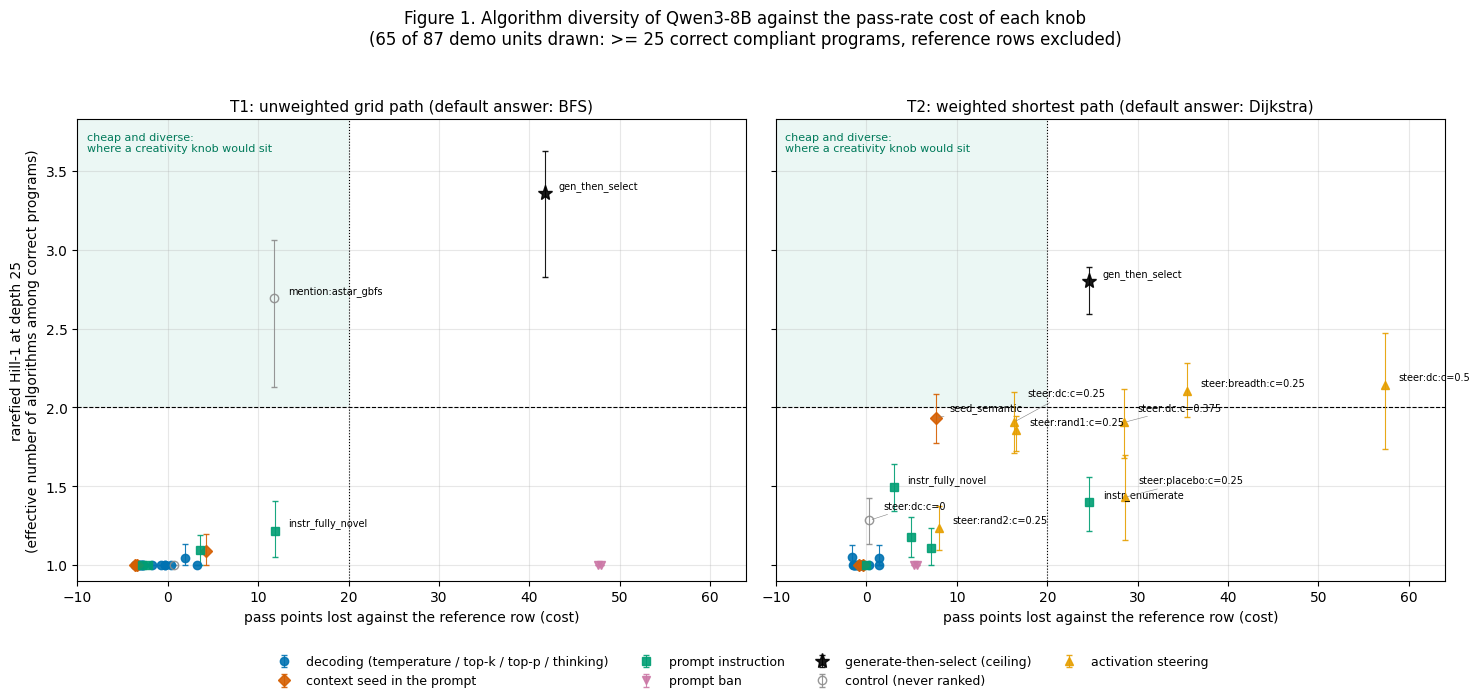

In [17]:
tab = pd.DataFrame(knob["primary"])
tab["hill"] = tab["hill_rar25"].map(_num)
tab["lo"] = tab["hill_rar25_ci90"].map(lambda v: _num(v[0]))
tab["hi"] = tab["hill_rar25_ci90"].map(lambda v: _num(v[1]))
tab["pts"] = tab["pass_points"].map(_num)
tab["x"] = tab["pts"] + np.random.default_rng(0).uniform(-0.7, 0.7, len(tab))   # small jitter: many units overlap

KIND = {"decoding setting": "decoding (temperature / top-k / top-p / thinking)",
        "seed": "context seed in the prompt", "instruction": "prompt instruction",
        "prompt ban (single, multi or two-step)": "prompt ban",
        "activation intervention (steering / removal / random direction)": "activation steering",
        "activation intervention on a ban prompt (KV splice / attention knockout)": "activation steering"}
STYLE = {"decoding (temperature / top-k / top-p / thinking)": dict(color="#0072B2", marker="o"),
         "context seed in the prompt": dict(color="#D55E00", marker="D"),
         "prompt instruction": dict(color="#009E73", marker="s"),
         "prompt ban": dict(color="#CC79A7", marker="v"),
         "activation steering": dict(color="#E69F00", marker="^"),
         "generate-then-select (ceiling)": dict(color="black", marker="*"),
         "control (never ranked)": dict(color="0.55", marker="o", mfc="none")}


def _kind(r):
    if r["class"] == "KNOB":
        return KIND.get(r["class_reason"], "other knob")
    return {"CEILING": "generate-then-select (ceiling)", "CONTROL": "control (never ranked)"}.get(r["class"], "reference")


tab["kind"] = tab.apply(_kind, axis=1)
plotted = tab[tab["hill"].notna() & tab["pts"].notna()]
ymax = max(2.4, float(np.nanmax(plotted["hi"].fillna(plotted["hill"]))) + 0.2) if len(plotted) else 2.4
xmin = min(-10.0, float(plotted["pts"].min()) - 3) if len(plotted) else -10.0
xmax = max(MAX_POINTS + 10, float(plotted["pts"].max()) + 6) if len(plotted) else MAX_POINTS + 10

fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
for ax, task, title in zip(axes, ("t1", "t2"), ("T1: unweighted grid path (default answer: BFS)",
                                                "T2: weighted shortest path (default answer: Dijkstra)")):
    sub = plotted[plotted["task"] == task]
    ax.fill_between([xmin, MAX_POINTS], 2, ymax, color="#009E73", alpha=0.08, lw=0)
    ax.text(xmin + 1, ymax - 0.08, "cheap and diverse:\nwhere a creativity knob would sit", va="top", fontsize=8,
            color="#007a5a")
    ax.axhline(2, color="k", ls="--", lw=0.8)
    ax.axvline(MAX_POINTS, color="k", ls=":", lw=0.8)
    for kname, st in STYLE.items():
        s = sub[sub["kind"] == kname]
        if s.empty:
            continue
        yerr = np.vstack([(s["hill"] - s["lo"]).clip(lower=0).fillna(0), (s["hi"] - s["hill"]).clip(lower=0).fillna(0)])
        ax.errorbar(s["x"], s["hill"], yerr=yerr, fmt=st["marker"], color=st["color"], mfc=st.get("mfc", st["color"]),
                    ms=11 if st["marker"] == "*" else 6, elinewidth=0.8, capsize=2, alpha=0.9, label=kname)
    placed = []   # simple label de-overlap: push a label up while it collides with one already placed
    for _, r in sub[sub["hill"] >= 1.2].sort_values("hill").iterrows():
        ty = r["hill"]
        moved = True
        while moved:          # ty only ever increases, so this ends after at most len(placed) moves
            moved = False
            for px, py in placed:
                if abs(px - r["x"]) < 15 and abs(py - ty) < 0.085 and py + 0.09 > ty:
                    ty, moved = py + 0.09, True
        placed.append((r["x"], ty))
        ax.annotate(r["condition"].replace(":L=18", ""), (r["x"], r["hill"]),
                    xytext=(r["x"] + 1.5, ty + 0.03), textcoords="data", fontsize=7,
                    arrowprops=dict(arrowstyle="-", lw=0.4, color="0.5") if ty > r["hill"] + 1e-9 else None)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("pass points lost against the reference row (cost)")
    ax.set_xlim(xmin, xmax)
    ax.grid(alpha=0.3)
axes[0].set_ylim(0.9, ymax)
axes[0].set_ylabel("rarefied Hill-1 at depth 25\n(effective number of algorithms among correct programs)")
handles, labels = [], []
for ax in axes:
    for h, l in zip(*ax.get_legend_handles_labels()):
        if l not in labels:
            handles.append(h)
            labels.append(l)
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, fontsize=9)
fig.suptitle("Figure 1. Algorithm diversity of Qwen3-8B against the pass-rate cost of each knob\n"
             f"({len(plotted)} of {len(tab)} demo units drawn: >= {DEPTH} correct compliant programs, "
             "reference rows excluded)", fontsize=12)
plt.tight_layout(rect=(0, 0.08, 1, 0.95))
plt.show()

**Figure 2: is temperature the creativity knob?** This is the exp6 decoding grid. Rows are temperatures. Columns are
the truncation setting (top-k 10 or top-p 0.95) crossed with thinking off or on, plus the untruncated default
(T = 1.0 only). Each cell shows the rarefied Hill-1, and below it the most common algorithm among correct programs
with its count.

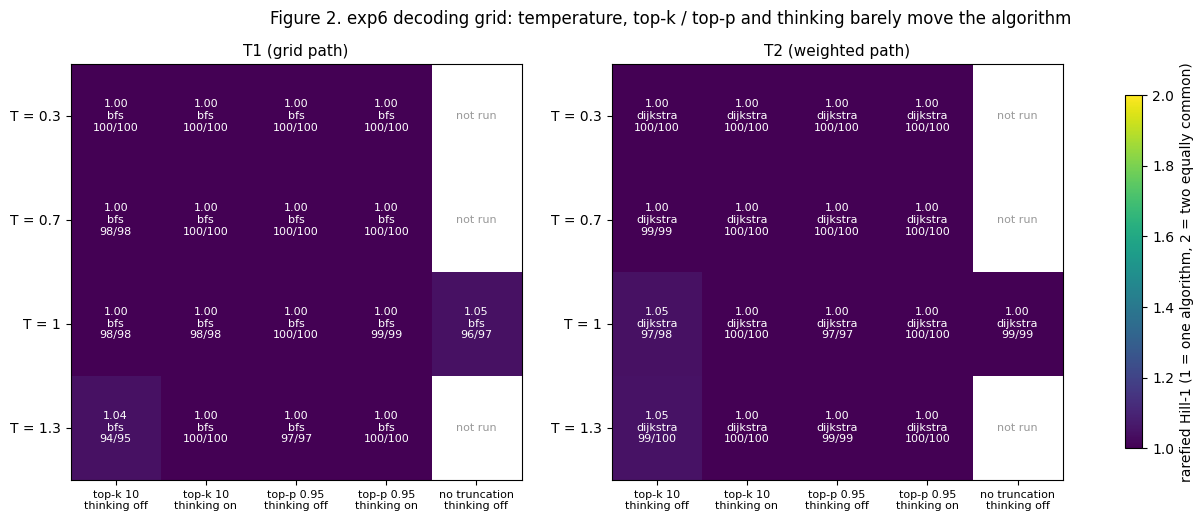

decoding grid: rarefied Hill-1 ranges 1.000-1.049 over 34 cells


In [18]:
g = tab[(tab["exp"] == "exp6") & (tab["condition"] == "baseline")].copy()
if g.empty:
    print("no exp6 decoding units in this run -- raise N_UNITS to include them")
else:
    def _col(dec):
        T, k, p, th = dec.split("|")
        trunc = "top-k 10" if k == "k10" else ("top-p 0.95" if p == "p0.95" else "no truncation")
        return float(T[1:]), f"{trunc}\nthinking {'on' if th == 'thinkTrue' else 'off'}"

    g["T"], g["col"] = zip(*g["decoding"].map(_col))
    cols = ["top-k 10\nthinking off", "top-k 10\nthinking on", "top-p 0.95\nthinking off", "top-p 0.95\nthinking on",
            "no truncation\nthinking off"]
    Ts = sorted(g["T"].unique())
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.4))
    for ax, task in zip(axes, ("t1", "t2")):
        M = np.full((len(Ts), len(cols)), np.nan)
        A = [["not run"] * len(cols) for _ in Ts]
        for _, r in g[g["task"] == task].iterrows():
            i, j = Ts.index(r["T"]), cols.index(r["col"])
            M[i, j] = r["hill"]
            top = max(r["cc_counts"].items(), key=lambda kv: kv[1]) if r["cc_counts"] else ("-", 0)
            A[i][j] = f"{r['hill']:.2f}\n{top[0]}\n{top[1]}/{r['n_cc']}"
        im = ax.imshow(M, vmin=1, vmax=2, cmap="viridis", aspect="auto")
        for i in range(len(Ts)):
            for j in range(len(cols)):
                ax.text(j, i, A[i][j], ha="center", va="center", fontsize=8,
                        color="0.6" if np.isnan(M[i, j]) else ("white" if M[i, j] < 1.6 else "black"))
        ax.set_xticks(range(len(cols)), cols, fontsize=8)
        ax.set_yticks(range(len(Ts)), [f"T = {t:g}" for t in Ts])
        ax.set_title({"t1": "T1 (grid path)", "t2": "T2 (weighted path)"}[task], fontsize=11)
    fig.colorbar(im, ax=axes, shrink=0.85, label="rarefied Hill-1 (1 = one algorithm, 2 = two equally common)")
    fig.suptitle("Figure 2. exp6 decoding grid: temperature, top-k / top-p and thinking barely move the algorithm",
                 fontsize=12)
    plt.show()
    print(f"decoding grid: rarefied Hill-1 ranges {g['hill'].min():.3f}-{g['hill'].max():.3f} over {len(g)} cells")

**Figure 3: where does the mass go?** Each bar is the composition of one unit's correct compliant programs, as shares
of the catalogue algorithms. The units shown are:

* the prompt-level knobs of exp6, the modal bans of exp1 and exp9, and generate-then-select;
* the exp4 activation-steering arms on T2. The dc arms add c·‖h‖ times the list-versus-implement direction `d_dc` at
  every token; the others use a "breadth" direction, two random directions and a variable-name placebo direction.

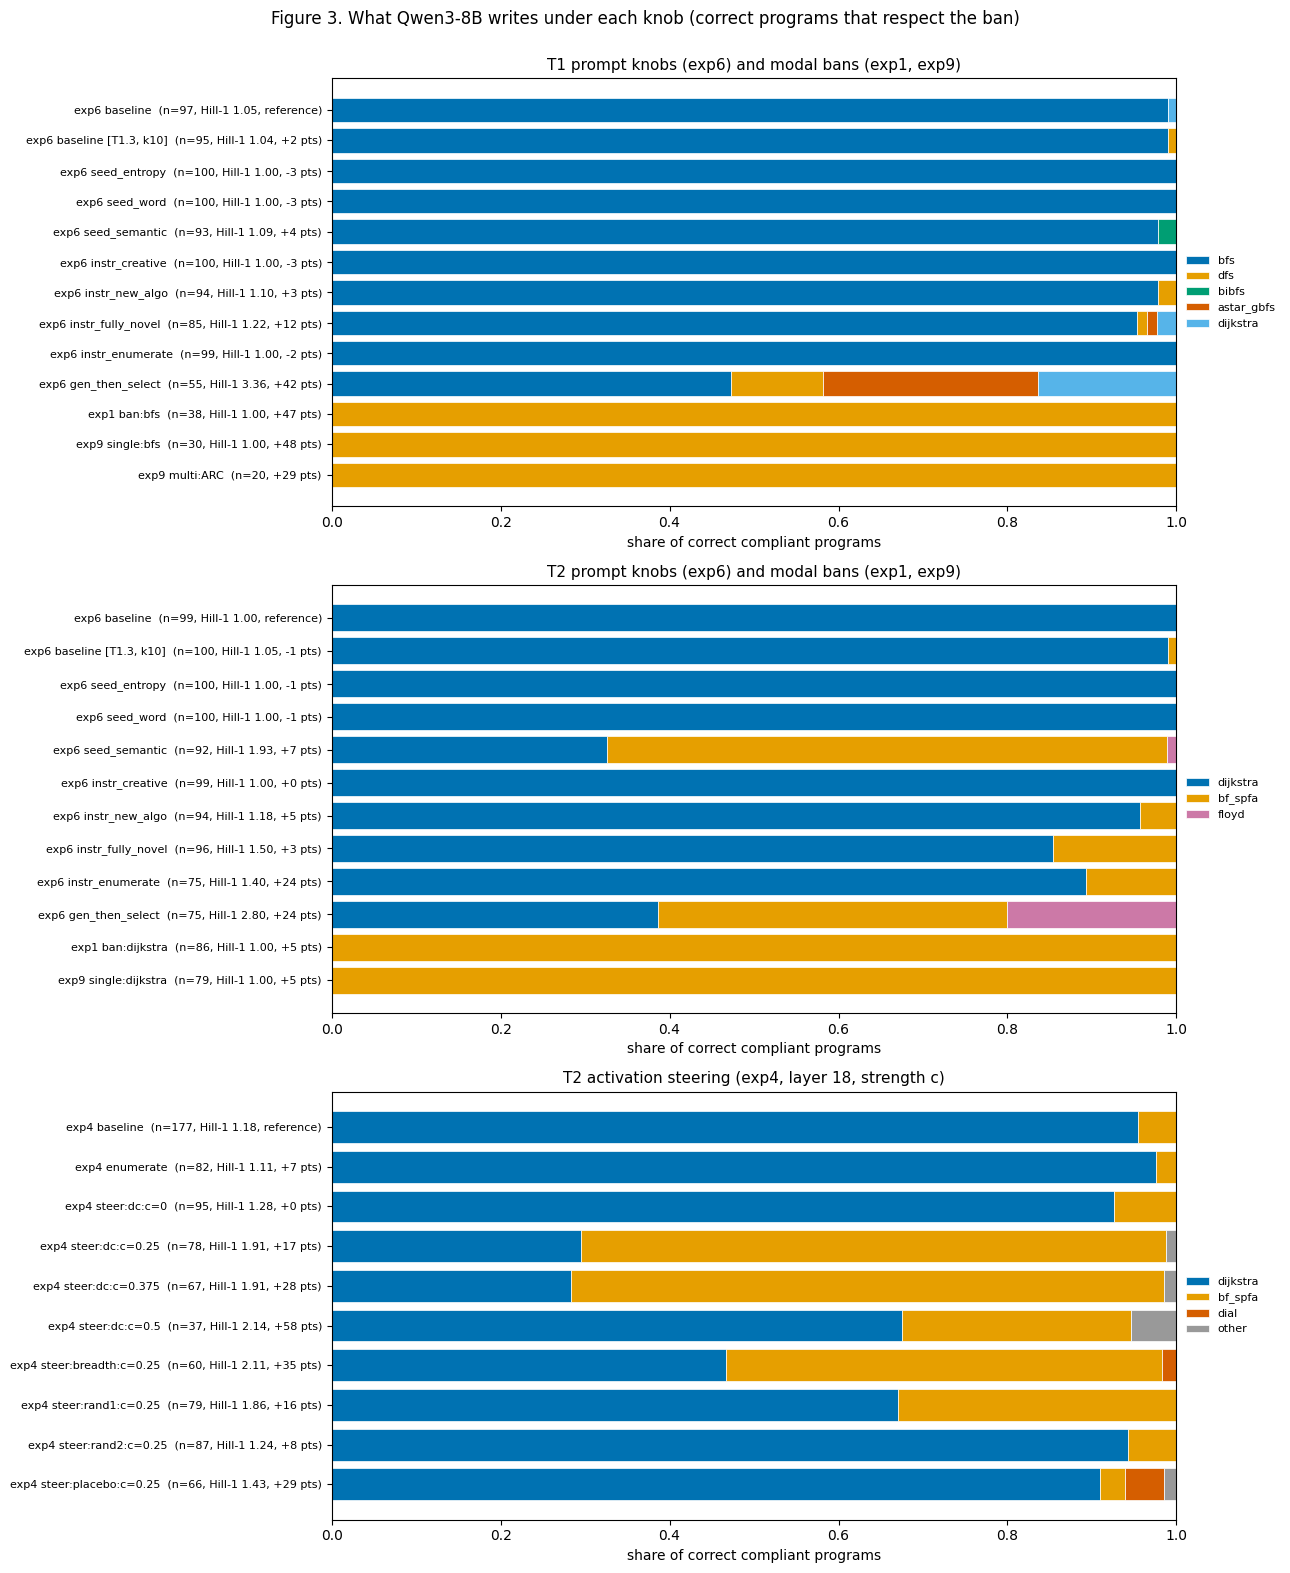

In [19]:
CAT = {"t1": T1_K6 + ["idastar"], "t2": T2_K5}
PALETTE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9", "#F0E442"]
PROMPT_KNOBS = [("baseline", DEFAULT_DEC), ("baseline", "T1.3|k10|p1.0|thinkFalse"), ("seed_entropy", DEFAULT_DEC),
                ("seed_word", DEFAULT_DEC), ("seed_semantic", DEFAULT_DEC), ("instr_creative", DEFAULT_DEC),
                ("instr_new_algo", DEFAULT_DEC), ("instr_fully_novel", DEFAULT_DEC), ("instr_enumerate", DEFAULT_DEC),
                ("gen_then_select", DEFAULT_DEC)]
PANELS = [
    ("t1", "T1 prompt knobs (exp6) and modal bans (exp1, exp9)",
     [("exp6",) + u for u in PROMPT_KNOBS] + [("exp1", "ban:bfs", DEFAULT_DEC), ("exp9", "single:bfs", DEFAULT_DEC),
                                             ("exp9", "multi:ARC", DEFAULT_DEC)]),
    ("t2", "T2 prompt knobs (exp6) and modal bans (exp1, exp9)",
     [("exp6",) + u for u in PROMPT_KNOBS] + [("exp1", "ban:dijkstra", DEFAULT_DEC),
                                             ("exp9", "single:dijkstra", DEFAULT_DEC)]),
    ("t2", "T2 activation steering (exp4, layer 18, strength c)",
     [("exp4", c, DEFAULT_DEC) for c in ("baseline", "enumerate", "steer:dc:c=0:L=18", "steer:dc:c=0.25:L=18",
                                          "steer:dc:c=0.375:L=18", "steer:dc:c=0.5:L=18", "steer:breadth:c=0.25:L=18",
                                          "steer:rand1:c=0.25:L=18", "steer:rand2:c=0.25:L=18",
                                          "steer:placebo:c=0.25:L=18")]),
]

fig, axes = plt.subplots(len(PANELS), 1, figsize=(13, 16))
for ax, (task, title, units) in zip(axes, PANELS):
    cats = CAT[task] + ["other"]
    colors = {c: PALETTE[i] for i, c in enumerate(CAT[task])} | {"other": "#999999"}
    labels, M = [], []
    for exp, cond, dec in units:
        r = tab[(tab["exp"] == exp) & (tab["task"] == task) & (tab["condition"] == cond) & (tab["decoding"] == dec)]
        if r.empty:
            continue
        r = r.iloc[0]
        cc, n = r["cc_counts"], r["n_cc"]
        row = [cc.get(c, 0) for c in CAT[task]]
        row.append(n - sum(row))
        M.append(np.array(row, dtype=float) / max(n, 1))
        dec_s = "" if dec == DEFAULT_DEC else f" [{dec.split('|')[0]}, {dec.split('|')[1]}]"
        h_s = f", Hill-1 {r['hill']:.2f}" if np.isfinite(r["hill"]) else ""
        p_s = f", {r['pts']:+.0f} pts" if np.isfinite(r["pts"]) else ", reference"
        labels.append(f"{exp} {cond.replace(':L=18', '')}{dec_s}  (n={n}{h_s}{p_s})")
    if not M:
        ax.text(0.5, 0.5, "these units are not in this run -- raise N_UNITS", ha="center", va="center",
                transform=ax.transAxes)
        ax.set_title(title, fontsize=11)
        ax.set_axis_off()
        continue
    M = np.array(M)
    left = np.zeros(len(M))
    for j, c in enumerate(cats):
        ax.barh(range(len(M)), M[:, j], left=left, color=colors[c], edgecolor="white", lw=0.5,
                label=c if M[:, j].sum() > 0 else "_nolegend_")
        left += M[:, j]
    ax.set_yticks(range(len(M)), labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of correct compliant programs")
    ax.set_title(title, fontsize=11)
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8, frameon=False)
fig.suptitle("Figure 3. What Qwen3-8B writes under each knob (correct programs that respect the ban)", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

## What the knob table says

The numbers below are from the published table. This notebook reproduces its exact fields and matches its Monte-Carlo
fields to within simulation noise.

**Temperature is not a creativity knob.** The exp6 grid crosses 4 temperatures with top-k 10 or top-p 0.95 and with
thinking off or on. Across it, the rarefied Hill-1 never goes above about 1.05 (Figure 2), and exp1's T = 1.3 run
stays at 1.00. Qwen3-8B writes BFS on T1 and Dijkstra on T2 whatever the sampler does. Sampling diversity does not
turn into algorithm diversity.

**Context matters only when it carries an algorithm.**

* *Random seed strings change nothing.* `seed=d32qxk4nt43` and `seed=(horse chair roof love)` give Hill-1 = 1.00.
* *A semantic seed does.* A short story that describes another algorithm's mechanism moves T2 to BF/SPFA 61 and
  Dijkstra 30. That is Hill-1 1.94 [1.77, 2.09] for 7 pass points, the best knob in the whole table. On T1 the two
  hikers story barely moves BFS (1.09).

This fits the "context pushes the model into a different subspace" picture, but the push lands on a known algorithm,
not a new one.

**Instructions do little.** "Be creative." gives 1.00. "Make a fully novel algorithm never seen before." gives
1.23 (T1) and 1.50 (T2). "List 10 approaches, then implement one" gives 1.39 on T2, at 24 pass points.

**Bans substitute; they do not diversify.**

* *Single bans.* Banning BFS on T1 sends every correct compliant program to DFS (exp1: 38 of 38, Hill-1 1.00, at 47
  pass points). Banning Dijkstra on T2 sends them all to Bellman-Ford/SPFA (exp1: 86 of 86; exp9: 79 of 79).
* *Bans of four or five names at once* (exp9 TOP, TOP5, ARC, SCATTER) are largely ignored: 59 to 69 of 100 programs
  are still BFS. Fewer than 25 correct programs respect the ban, so these rows cannot be ranked.

**Steering and generate-then-select buy diversity at a price.** Steering along `d_dc` at c = 0.25 reaches 1.91 on T2
for 17 points. A random direction does about as well (1.86 for 16 points), so the effect is not specific to the
direction. Letting an external RNG pick one of 10 listed approaches reaches 3.3 (T1) and 2.8 (T2), at a cost of 24
to 42 pass points.

**Novelty.** The artifact's novelty audit (section 0c, not run here) finds that none of the 78 unique correct
out-of-catalogue programs is a novel algorithm (95% upper bound 3/78 = 0.038). The knobs move Qwen3-8B between
**known** algorithms. None of them produces a new one.

**Scaling this demo.** The configuration cell already uses the original Monte-Carlo sizes (1,000 subsamples; 2,000 ×
200 bootstrap draws) on all 87 demo units, and the section takes a few seconds. To rebuild all 306 units, plus the
Qwen3-8B-Base and Llama tables, run `uv run eval.py --section knob` in the repository with the dependency artifacts in
place.